In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from Models import aggregate_model

P* = 0.014726087415578133  S* = 0.07523458581705023
max variazione relativa P: 0.0
max variazione relativa S: 0.0


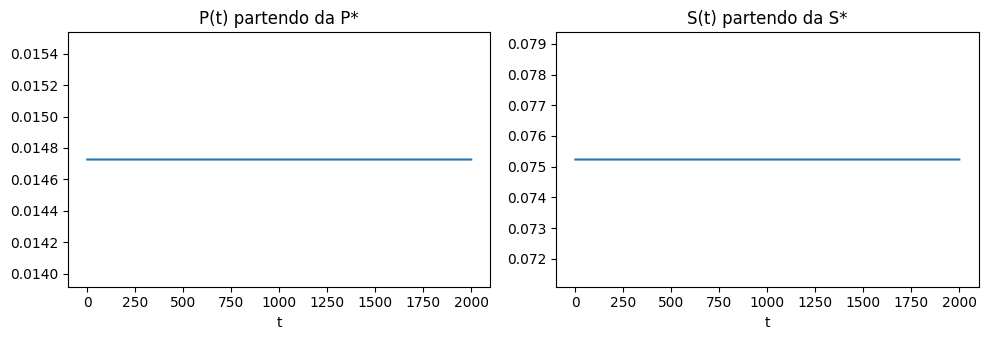

In [2]:
# 1. Parametri fittati
par = pd.read_csv("best_fit_ebm.csv").iloc[0][["c", "m", "n", "d", "k", "R"]].to_dict()

# 2. Equilibrio interno
def interior_equilibrium(c, m, n, d, k, R):
    S_star = (n - m) / (k * m)
    A_star = S_star * d / (1 - d)
    P_star = R * A_star / (c * (1 + S_star))
    return P_star, S_star

P_star, S_star = interior_equilibrium(**par)
print("P* =", P_star, " S* =", S_star)

# 3. Verifica: si parte esattamente dal punto fisso
T = 2000
S_ts, P_ts = aggregate_model(T, **par, P_0=P_star, S_0=S_star)

print("max variazione relativa P:", np.max(np.abs(np.array(P_ts) - P_star)) / P_star)
print("max variazione relativa S:", np.max(np.abs(np.array(S_ts) - S_star)) / S_star)

# 4. Grafico
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(P_ts); ax[0].set_title("P(t) partendo da P*"); ax[0].set_xlabel("t")
ax[1].plot(S_ts); ax[1].set_title("S(t) partendo da S*"); ax[1].set_xlabel("t")
plt.tight_layout()
plt.show()